In [1]:
# Notebooks live in Notebooks/, but every data path is relative to the repo root.
import os, sys
while not os.path.isdir("data") and os.getcwd() != "/":
    os.chdir("..")
if os.getcwd() not in sys.path:
    sys.path.insert(0, os.getcwd())
print("cwd:", os.getcwd())

cwd: /home/user1/WhatDoLLMsWant


# Books, full 48 — what do the models want, and what does a contract do? (2026-10-13)

`data/books/`: 4 instruct models (qwen-32B, qwen-72B, gemma-27B, olmo-32B) × `none` + 4 tag contracts
(`fantasy`, `mystery-thriller`, `romance`, `classics`), frame `reading`, 48 famous Goodreads books shown as
`"<title> by <author> (<year>)"`; the 8 genre tags are hidden. Design:
[books_domain_design.ipynb](books_domain_design.ipynb); pilot: [books_pilot.ipynb](books_pilot.ipynb).

Every "who wins" number uses the position-corrected $D = (m(x,y) - m(y,x))/2$; a book's **score** is its mean
$D$ against the other 47 (Borda). Scores are zero-sum across books: only relative standing is measurable.

Sections: 1 sanity · 2 the default ranking · 3 what explains it · 4 contracts · 5 inside the contract ·
6 findings.

In [2]:
import json, glob
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
from src.bt import FeatureBT
import src.alternatives as alt
from src.books import make_books as mb
pd.set_option("display.width", 250); pd.set_option("display.max_rows", 200); pd.set_option("display.max_columns", 30)

TAGS = alt.book_tags
BOOK = {b["title"]: b for b in alt.books}
meta = pd.read_csv("src/books/books.csv").set_index("title")
MODELS = ["qwen-32B", "qwen-72B", "gemma-27B", "olmo-32B"]
CONS = ["none", "fantasy=yes", "mystery-thriller=yes", "romance=yes", "classics=yes"]
FIG = "figs/books"; os.makedirs(FIG, exist_ok=True)

# Palette (dataviz reference, validated): blue = the contract / the requested tag, gray = baseline / other.
BLUE, GRAY, INK, INK2 = "#2a78d6", "#a3a29d", "#0b0b0b", "#52514e"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": INK2,
                     "axes.labelcolor": INK, "xtick.color": INK2, "ytick.color": INK2, "font.size": 10,
                     "axes.titlesize": 11, "figure.facecolor": "white"})

runs = {}
for f in sorted(glob.glob("data/books/*/config.json")):
    d = os.path.dirname(f)
    if not os.path.isfile(d + "/scores.csv"):        # incomplete or still running: skip
        print("skip (no scores.csv):", d); continue
    c = json.load(open(f))
    assert c["frame"]["name"] == "reading"
    k = (f"{c['model_family']}-{c['model_size']}B", c["constraints_id"])
    assert k not in runs, f"duplicate run {k}"
    runs[k] = pd.read_csv(d + "/scores.csv")
    assert len(runs[k]) == 48 * 47 * 5, (k, len(runs[k]))
print(len(runs), "runs; missing:", [(m, c) for m in MODELS for c in CONS if (m, c) not in runs])

20 runs; missing: []


In [3]:
def Dtab(df):
    """position-corrected D per (template, ordered pair); both orders present"""
    m = df.assign(m=df.score_a - df.score_b)[["template_idx", "a_title", "b_title", "m"]]
    r = m.rename(columns={"a_title": "b_title", "b_title": "a_title"}).assign(m=-m.m)
    return pd.concat([m, r]).groupby(["template_idx", "a_title", "b_title"]).m.mean().reset_index()

D = {k: Dtab(df) for k, df in runs.items()}
score = {k: d.groupby("a_title").m.mean() for k, d in D.items()}       # Borda score per book
has = lambda b, t: BOOK[b][t] == "yes"

## 1. Sanity

`sat` = share of rows where the winner's log-prob is ≈ 0; `gamma` = mean raw margin (slot A − slot B; content
cancels because every pair appears in both orders); `tmpl_agree` = mean Spearman between the 5 templates' book
rankings; `spread` = SD of the 48 book scores (how loud the preference is).

In [4]:
rows = []
for (m, c), df in runs.items():
    mm = df.score_a - df.score_b
    t = D[(m, c)].groupby(["a_title", "template_idx"]).m.mean().unstack().corr(method="spearman").values
    rows.append(dict(model=m, contract=c, sat=(df[["score_a", "score_b"]].max(axis=1) > -0.1).mean(),
                     gamma=mm.mean(), tmpl_agree=t[np.triu_indices_from(t, 1)].mean(), spread=score[(m, c)].std()))
SAN = pd.DataFrame(rows).set_index(["model", "contract"]).reindex([(m, c) for m in MODELS for c in CONS]).dropna(how="all")
SAN.round(2)

sat  gamma  tmpl_agree  spread
model     contract                                             
qwen-32B  none                  0.87   6.40        0.98    5.64
          fantasy=yes           0.94  -7.37        0.99   12.58
          mystery-thriller=yes  0.89  -5.80        1.00   13.02
          romance=yes           0.90  -5.36        1.00   13.09
          classics=yes          0.93  -1.41        1.00   15.65
qwen-72B  none                  0.74   2.08        0.98    4.50
          fantasy=yes           0.79  -5.02        0.99   10.12
          mystery-thriller=yes  0.84  -4.92        0.99   10.18
          romance=yes           0.85  -5.43        1.00    9.94
          classics=yes          0.91  -3.17        1.00   11.54
gemma-27B none                  0.98   5.73        0.99    8.71
          fantasy=yes           0.98   4.80        1.00   11.48
          mystery-thriller=yes  0.98   4.89        0.99   11.11
          romance=yes           0.98   5.01        1.00   11.86
          classics=yes          0.99   4.48        1.00   12.21
olmo-32B  none                  0.08   0.34        0.97    0.87
          fantasy=yes           0.90  -2.77        0.95    4.46
          mystery-thriller=yes  0.74  -1.30        0.99    3.97
          romance=yes           0.88  -2.89        0.98    4.61
          classics=yes          0.85  -1.01        1.00    5.26

All runs are clean: templates agree at 0.95–1.00. Two things to note:

- **olmo-32B without a contract is quiet** — 8% saturated, spread 0.9 vs 4.5–8.7 for the others — but stable
  (0.97) and content-driven (section 2). A real low-confidence default, not a bug. Any contract makes it confident.
- **In qwen the slot bias flips sign under a contract** (γ +2 / +6 → −3 … −7). Gemma's stays at +5. Same
  family-specific behaviour as on the laptops; `D` is immune to it.

## 2. The default ranking (no contract)

In [5]:
base = pd.DataFrame({m: score[(m, "none")] for m in MODELS})
rank = base.rank(ascending=False).astype(int)
order = rank.mean(axis=1).sort_values().index
print("Spearman between models (no contract):")
display(base.corr(method="spearman").round(2))
rank.loc[order].assign(mean=rank.loc[order].mean(axis=1).round(1),
                       tags=[", ".join(t for t in TAGS if has(b, t)) for b in order])

Spearman between models (no contract):


,qwen-32B,qwen-72B,gemma-27B,olmo-32B
qwen-32B,1.00,0.83,0.76,0.59
qwen-72B,0.83,1.00,0.79,0.65
gemma-27B,0.76,0.79,1.00,0.62
olmo-32B,0.59,0.65,0.62,1.00


,qwen-32B,qwen-72B,gemma-27B,olmo-32B,mean,tags
a_title,,,,,,
To Kill a Mockingbird,1,2,3,2,2.0,classics
The Hitchhiker's Guide to the Galaxy,4,3,1,3,2.8,"science-fiction, classics"
Harry Potter and the Sorcerer's Stone,5,1,7,1,3.5,"fantasy, young-adult"
The Book Thief,7,7,5,5,6.0,"young-adult, historical-fiction"
The Hobbit,6,5,11,4,6.5,"fantasy, classics"
The Kite Runner,10,10,2,8,7.5,"classics, historical-fiction"
1984,2,6,14,9,7.8,"science-fiction, classics"
The Diary of a Young Girl,3,11,4,31,12.2,"classics, nonfiction"
The Curious Incident of the Dog in the Night-Time,17,15,6,15,13.2,"mystery-thriller, young-adult, classics"


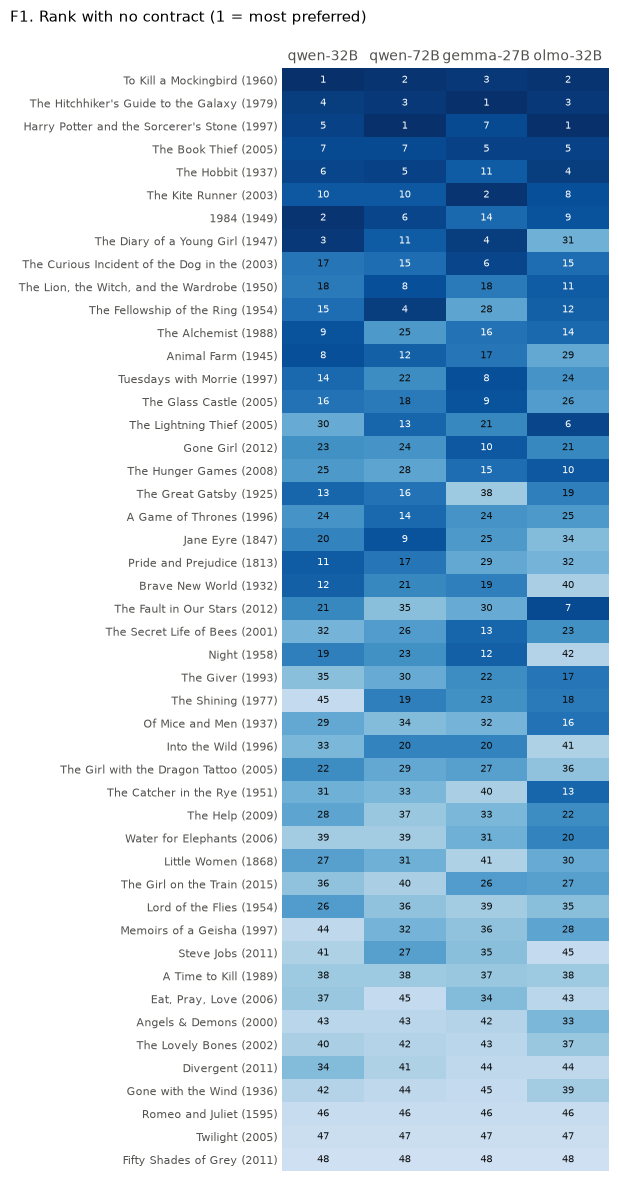

In [6]:
# F1: rank of every book per model (1 = most preferred), sorted by the mean rank.
fig, ax = plt.subplots(figsize=(6.2, 12))
R = rank.loc[order]
ax.imshow(R.values, cmap="Blues_r", vmin=1, vmax=60, aspect="auto")      # dark = preferred; capped so 48 stays readable
for i in range(R.shape[0]):
    for j in range(R.shape[1]):
        v = R.values[i, j]
        ax.text(j, i, v, ha="center", va="center", fontsize=7.5, color="white" if v <= 16 else INK)
ax.set_xticks(range(len(MODELS)), MODELS); ax.xaxis.tick_top()
ax.set_yticks(range(len(order)), [f"{b[:38]} ({BOOK[b]['year']})" for b in order], fontsize=8)
ax.tick_params(length=0); [s.set_visible(False) for s in ax.spines.values()]
fig.suptitle("F1. Rank with no contract (1 = most preferred)", x=0.01, ha="left", fontsize=11)
fig.tight_layout(rect=(0, 0, 1, 0.985)); fig.savefig(f"{FIG}/F1_default_rank.png", dpi=150); plt.show()

**The four models largely share one taste** (Spearman 0.59–0.83; the two qwens 0.83). The bottom three are
**the same in all four models**: Romeo and Juliet 46th, Twilight 47th, Fifty Shades of Grey 48th. The top is
To Kill a Mockingbird, The Hitchhiker's Guide to the Galaxy and Harry Potter (mean rank ≤ 4.2).

## 3. What explains the default?

(a) Goodreads: average rating (quality as readers judge it), ratings count (fame), year.
(b) The hidden tags: a fit-free view (mean score of tagged − untagged books) and the `FeatureBT` tag weights.

In [7]:
j = base.join(meta[["average_rating", "ratings_count", "year"]])
GR = pd.DataFrame({m: {c: spearmanr(j[m], j[c])[0] for c in ["average_rating", "ratings_count", "year"]} for m in MODELS})
GR.round(2)

,qwen-32B,qwen-72B,gemma-27B,olmo-32B
average_rating,0.42,0.52,0.43,0.47
ratings_count,0.24,0.09,-0.14,0.27
year,-0.32,-0.33,0.01,-0.01


In [8]:
gap = pd.DataFrame({m: {t: base[m][[has(b, t) for b in base.index]].mean() - base[m][[not has(b, t) for b in base.index]].mean()
                        for t in TAGS} for m in MODELS})
W, R2 = {}, {}
cols = ["score_a", "score_b"] + [f"a_{t}" for t in TAGS] + [f"b_{t}" for t in TAGS]
for m in MODELS:
    bt = FeatureBT(pmi_c=0.0, r2_warn=None).fit(runs[(m, "none")][cols])
    W[m] = {t: bt.weights_[t]["yes"] - bt.weights_[t]["no"] for t in TAGS}; R2[m] = bt.r2_
W = pd.DataFrame(W); W.loc["R2"] = pd.Series(R2)
print("mean score, tagged - untagged books (fit-free):"); display(gap.round(2))
print("FeatureBT tag weight (yes - no), and R2 of the tag-only fit:"); display(W.round(2))

mean score, tagged - untagged books (fit-free):


,qwen-32B,qwen-72B,gemma-27B,olmo-32B
fantasy,-0.42,1.77,-0.24,0.44
science-fiction,2.85,1.97,3.20,0.18
romance,-6.00,-5.58,-10.19,-0.86
mystery-thriller,-2.20,-1.82,-0.92,-0.08
young-adult,-0.97,-0.38,0.23,0.42
classics,3.80,3.31,2.82,0.33
historical-fiction,-0.21,-0.23,0.90,0.20
nonfiction,1.73,0.60,5.39,-0.34


FeatureBT tag weight (yes - no), and R2 of the tag-only fit:


,qwen-32B,qwen-72B,gemma-27B,olmo-32B
fantasy,-0.72,1.42,-0.36,0.27
science-fiction,1.71,0.98,3.88,0.01
romance,-6.08,-5.45,-9.41,-0.83
mystery-thriller,-1.13,-1.34,2.11,-0.08
young-adult,-0.45,-0.66,1.63,0.29
classics,3.31,2.74,3.58,0.30
historical-fiction,1.36,1.32,5.70,0.41
nonfiction,2.22,0.98,8.36,-0.13
R2,0.27,0.34,0.24,0.22


- **Quality, not fame.** Every model correlates with the readers' average rating (ρ 0.42–0.52) and not with
  the number of ratings (−0.14 … +0.27). qwen also leans old (ρ −0.32 with year); gemma and OLMo do not.
- **Romance is the disliked genre** in qwen and gemma (−5.6 to −10.2 log-odds vs untagged books; OLMo −0.9 on its
  quiet scale). Classics and science fiction are liked; gemma also likes nonfiction (+5.4).
- **The tags explain only a quarter of the default** (R² 0.22–0.34): the choice is mostly about the book itself.

## 4. Contracts: does the model comply, and what does it cost?

**Mixed pairs** = one book has the tag, the other does not. `win_none` / `win_con` = share of mixed pairs the
tagged book wins, without / with the contract; `D_none` < 0 means the contract asks for what the model does not
want. `rms_move` = RMS change of the 48 book scores. `in_topN` = how many of the N tagged books are in the top N.

In [9]:
rows = []
for m in MODELS:
    for c in CONS[1:]:
        if (m, c) not in D: continue
        t = c.split("=")[0]; out = {"model": m, "contract": t}
        for name, k in [("none", (m, "none")), ("con", (m, c))]:
            d = D[k]; mix = d[d.a_title.map(lambda b: has(b, t)) & ~d.b_title.map(lambda b: has(b, t))]
            out[f"win_{name}"] = (mix.m > 0).mean(); out[f"D_{name}"] = mix.m.mean()
        dl = score[(m, c)] - score[(m, "none")]; tagged = [b for b in dl.index if has(b, t)]
        out["rms_move"] = np.sqrt((dl ** 2).mean())
        out["in_topN"] = f"{int(score[(m, c)].rank(ascending=False)[tagged].le(len(tagged)).sum())}/{len(tagged)}"
        rows.append(out)
CT = pd.DataFrame(rows).set_index(["model", "contract"])
CT.round(2)

win_none  D_none  win_con  D_con  rms_move in_topN
model     contract                                                            
qwen-32B  fantasy               0.51   -0.41     0.95  23.67     12.72    7/10
          mystery-thriller      0.29   -2.15     1.00  30.18     14.50     8/8
          romance               0.23   -5.87     0.95  23.57     16.17     5/8
          classics              0.69    3.72     0.97  24.19     14.00   24/26
qwen-72B  fantasy               0.66    1.73     0.95  18.74      9.43    7/10
          mystery-thriller      0.33   -1.78     1.00  23.95     11.24     8/8
          romance               0.15   -5.47     0.96  18.77     12.80     6/8
          classics              0.70    3.24     0.98  18.11     10.43   23/26
gemma-27B fantasy               0.52   -0.23     0.96  19.99     13.74    8/10
          mystery-thriller      0.45   -0.90     1.00  23.15     13.15     8/8
          romance               0.18   -9.98     0.94  19.95     17.54     6/8
          classics              0.60    2.76     0.95  18.41     14.27   22/26
olmo-32B  fantasy               0.67    0.43     0.93   7.95      4.18    8/10
          mystery-thriller      0.42   -0.07     0.97   8.55      3.88     6/8
          romance               0.28   -0.84     0.96   8.64      4.92     5/8
          classics              0.60    0.32     0.97   8.21      5.15   24/26

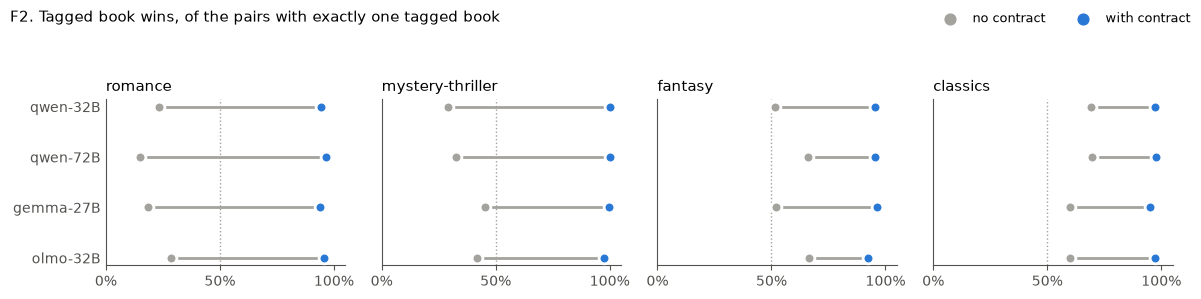

In [10]:
# F2: share of mixed pairs won by the tagged book, without -> with the contract.
fig, axes = plt.subplots(1, 4, figsize=(12, 3.0), sharey=True)
for ax, t in zip(axes, ["romance", "mystery-thriller", "fantasy", "classics"]):
    sub = CT.xs(t, level="contract").reindex(MODELS)
    y = np.arange(len(MODELS))[::-1]
    for yi, m in zip(y, MODELS):
        if m not in sub.dropna().index:
            ax.text(0.5, yi, "not landed yet", ha="center", va="center", fontsize=8, color=INK2); continue
        a, b = sub.loc[m, "win_none"], sub.loc[m, "win_con"]
        ax.plot([a, b], [yi, yi], color=GRAY, lw=2, zorder=1)
        ax.scatter([a], [yi], s=60, color=GRAY, zorder=2, edgecolor="white", linewidth=2)
        ax.scatter([b], [yi], s=60, color=BLUE, zorder=3, edgecolor="white", linewidth=2)
    ax.axvline(0.5, color=GRAY, lw=1, ls=":", zorder=0)
    ax.set_xlim(0, 1.05); ax.set_xticks([0, .5, 1], ["0%", "50%", "100%"]); ax.set_title(t, loc="left")
    ax.set_yticks(y, MODELS); ax.tick_params(axis="y", length=0)
axes[0].scatter([], [], color=GRAY, s=60, label="no contract"); axes[0].scatter([], [], color=BLUE, s=60, label="with contract")
fig.legend(loc="upper right", frameon=False, ncol=2, fontsize=9)
fig.suptitle("F2. Tagged book wins, of the pairs with exactly one tagged book", x=0.01, ha="left", fontsize=11)
fig.tight_layout(rect=(0, 0, 1, 0.9)); fig.savefig(f"{FIG}/F2_contract_win_rate.png", dpi=150); plt.show()

- **Every contract is obeyed, even against the default**: 93–100% of mixed pairs, in every model.
  `romance` is the hardest test (the model's default is 15–28%) and still reaches 94–96%.
- **Fifty Shades of Grey goes from 48th to 4th–5th** under `romance`, in all four models. The model's
  strongest dislike is gone with one sentence.
- **`classics` was meant as the control** (it agrees with the default, like `ram=16GB` on the laptops). It is
  not: it moves the scores as much as the other contracts (RMS 5–16 vs 4–18). Section 5 shows why.

In [11]:
for b in ["Fifty Shades of Grey", "Twilight", "Harry Potter and the Sorcerer's Stone", "To Kill a Mockingbird", "The Hitchhiker's Guide to the Galaxy"]:
    print(f"{b[:36]:36} tags: {', '.join(t for t in TAGS if has(b, t))}")
    display(pd.DataFrame({m: {c.split('=')[0]: int(score[(m, c)].rank(ascending=False)[b]) for c in CONS if (m, c) in score} for m in MODELS}).T)

Fifty Shades of Grey                 tags: romance


,none,fantasy,mystery-thriller,romance,classics
qwen-32B,48,47,39,4,48
qwen-72B,48,47,43,4,48
gemma-27B,48,42,34,5,48
olmo-32B,48,48,47,5,48


Twilight                             tags: fantasy, young-adult


,none,fantasy,mystery-thriller,romance,classics
qwen-32B,47,13,25,7,47
qwen-72B,47,8,22,3,46
gemma-27B,47,8,30,3,46
olmo-32B,47,8,22,2,46


Harry Potter and the Sorcerer's Ston tags: fantasy, young-adult


,none,fantasy,mystery-thriller,romance,classics
qwen-32B,5,1,17,21,34
qwen-72B,1,2,16,23,31
gemma-27B,7,2,15,18,30
olmo-32B,1,1,14,22,28


To Kill a Mockingbird                tags: classics


,none,fantasy,mystery-thriller,romance,classics
qwen-32B,1,36,16,20,9
qwen-72B,2,29,17,29,5
gemma-27B,3,41,18,29,9
olmo-32B,2,27,17,25,5


The Hitchhiker's Guide to the Galaxy tags: science-fiction, classics


,none,fantasy,mystery-thriller,romance,classics
qwen-32B,4,7,20,38,20
qwen-72B,3,7,29,34,21
gemma-27B,1,11,28,36,24
olmo-32B,3,12,25,43,25


## 5. Inside the contract: the model's taste, or "the most typical book of the genre"?

The contract says *which* genre; it does not say which fantasy book. If the model completed it with its own
preference, the tagged books would keep their default order. Test against **typicality** = the book's share of
that genre among its Goodreads genre shelves (from `make_books.genre_shares`).

In [12]:
share = mb.genre_shares(mb.load_raw()[1])
gid = meta.goodreads_book_id
rows = []
for m in MODELS:
    for c in CONS[1:]:
        if (m, c) not in score: continue
        t = c.split("=")[0]; b0, b1 = score[(m, "none")], score[(m, c)]
        sh = pd.Series({b: share.loc[gid[b], t] for b in b1.index})
        tg = [b for b in b1.index if has(b, t)]
        rows.append({"model": m, "contract": t,
                     "tagged: rho(score, default)": spearmanr(b1[tg], b0[tg])[0],
                     "tagged: rho(score, typicality)": spearmanr(b1[tg], sh[tg])[0],
                     "all 48: rho(move, typicality)": spearmanr(b1 - b0, sh)[0]})
TY = pd.DataFrame(rows).set_index(["model", "contract"])
TY.round(2)

tagged: rho(score, default)  tagged: rho(score, typicality)  all 48: rho(move, typicality)
model     contract                                                                                                    
qwen-32B  fantasy                                  0.84                            0.78                           0.72
          mystery-thriller                         0.14                            0.86                           0.60
          romance                                  0.10                            0.02                           0.85
          classics                                 0.20                            0.70                           0.84
qwen-72B  fantasy                                  0.87                            0.83                           0.73
          mystery-thriller                        -0.02                            0.86                           0.57
          romance                                  0.24                            0.55                           0.83
          classics                                 0.01                            0.70                           0.82
gemma-27B fantasy                                  0.52                            0.87                           0.67
          mystery-thriller                         0.24                            0.88                           0.60
          romance                                  0.29                            0.24                           0.84
          classics                                -0.34                            0.58                           0.66
olmo-32B  fantasy                                  0.75                            0.87                           0.79
          mystery-thriller                         0.00                            0.86                           0.70
          romance                                  0.36                            0.26                           0.81
          classics                                -0.36                            0.77                           0.90

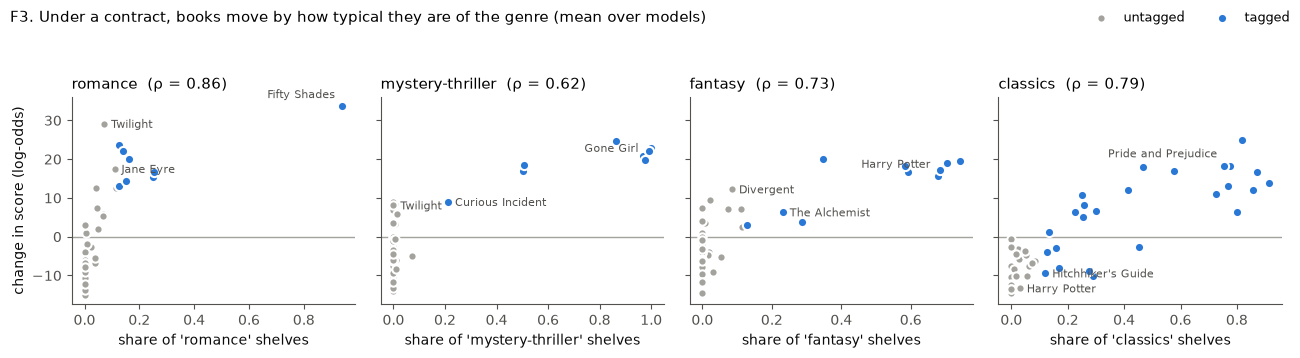

In [13]:
# F3: per contract, how much each book moved (mean over models) against how typical it is of the genre.
fig, axes = plt.subplots(1, 4, figsize=(13, 3.6), sharey=True)
LABEL = {"romance": ["Twilight", "Fifty Shades of Grey", "Jane Eyre"],
         "mystery-thriller": ["The Curious Incident of the Dog in the Night-Time", "Gone Girl", "Twilight"],
         "fantasy": ["Divergent", "The Alchemist", "Harry Potter and the Sorcerer's Stone"],
         "classics": ["The Hitchhiker's Guide to the Galaxy", "Pride and Prejudice", "Harry Potter and the Sorcerer's Stone"]}
SHORT = {"The Curious Incident of the Dog in the Night-Time": "Curious Incident", "Harry Potter and the Sorcerer's Stone": "Harry Potter",
         "The Hitchhiker's Guide to the Galaxy": "Hitchhiker's Guide", "Fifty Shades of Grey": "Fifty Shades"}
for ax, t in zip(axes, ["romance", "mystery-thriller", "fantasy", "classics"]):
    c = f"{t}=yes"; ms = [m for m in MODELS if (m, c) in score]
    dl = pd.concat([score[(m, c)] - score[(m, "none")] for m in ms], axis=1).mean(axis=1)
    sh = pd.Series({b: share.loc[gid[b], t] for b in dl.index})
    tg = np.array([has(b, t) for b in dl.index])
    ax.axhline(0, color=GRAY, lw=1, zorder=0)
    ax.scatter(sh[~tg], dl[~tg], s=36, color=GRAY, edgecolor="white", linewidth=1.5, label="untagged", zorder=2)
    ax.scatter(sh[tg], dl[tg], s=44, color=BLUE, edgecolor="white", linewidth=1.5, label=f"tagged", zorder=3)
    for b in LABEL[t]:
        ax.annotate(SHORT.get(b, b), (sh[b], dl[b]), xytext=(5, -3) if sh[b] < 0.5 else (-5, 6), ha="left" if sh[b] < 0.5 else "right", textcoords="offset points", fontsize=8, color=INK2)
    ax.set_title(f"{t}  (ρ = {spearmanr(dl, sh)[0]:.2f})", loc="left"); ax.set_xlabel(f"share of '{t}' shelves")
axes[0].set_ylabel("change in score (log-odds)")
fig.legend(*axes[0].get_legend_handles_labels(), loc="upper right", frameon=False, ncol=2, fontsize=9)
fig.suptitle("F3. Under a contract, books move by how typical they are of the genre (mean over models)", x=0.01, ha="left", fontsize=11)
fig.tight_layout(rect=(0, 0, 1, 0.92)); fig.savefig(f"{FIG}/F3_typicality.png", dpi=150); plt.show()

- **Inside the requested genre, the order follows typicality, not the model's taste.** Among tagged books the
  rank correlation with typicality is 0.58–0.88 (except `romance`); with the model's own default it is −0.36 to
  +0.36 (except `fantasy`). Across all 48 books, how far a book moves correlates 0.57–0.90 with how typical it is.
- **`fantasy` is the exception that proves it**: there the most typical book is also a favourite (Harry Potter),
  so taste and typicality agree (0.52–0.87 both).
- **`classics` reshuffles because of this.** Harry Potter (rank 1–7) falls to 28–34; The Hitchhiker's Guide
  (classics-tagged, 1–4) and The Kite Runner fall too; Pride and Prejudice rises. "Classics" means *the canonical
  classics*, not "the good books I already liked".
- **The model has its own idea of the genre.** Twilight is not tagged romance (7% of shelves) but rises the most
  under `romance` (+29.1 on average, from 47th to 2nd–7th); Jane Eyre (+17.5) and Little Women (+12.6) follow.
  Under `fantasy` the untagged dystopias rise (Divergent +12.3, The Giver +7.0) about as much as the tagged
  Alchemist (+6.3), while the typical fantasy books rise ~15–20.
- **Romance is the exception to typicality among tagged books** (ρ 0.02–0.55): what rises are the canonical
  romances (Jane Eyre, Pride and Prejudice) and Twilight, not the books with the most romance shelves.

## 6. Findings

1. **One shared taste.** The 4 models agree (ρ 0.59–0.83) and share the same bottom three (Romeo and Juliet,
   Twilight, Fifty Shades). The taste follows the readers' rating (ρ 0.42–0.52), not fame. Romance is disliked.
2. **The tags explain little of it** (R² 0.22–0.34): the choice is about the book.
3. **Contracts are obeyed, even against the default**: 93–100% of mixed pairs. Under `romance`, Fifty Shades
   goes 48th → 4th–5th in all four models.
4. **The contract does not get completed with the model's taste.** Inside the requested genre the order follows
   how typical a book is of the genre (ρ 0.58–0.88), not the model's default (ρ ≈ 0). So "the agreeing contract"
   `classics` is not a control: it moves the scores as much as the others, and Harry Potter falls from the top to ~30th.
5. **The model's genre ≠ the readers' tags**: Twilight behaves as romance, Divergent as fantasy, The Alchemist does not.

All 20 runs are in (olmo-32B `romance`, job 1447796, landed 2026-10-13 and changes no conclusion).

**Open:** a contract that
names the genre *and* asks for quality ("I prefer good fantasy") would show whether the taste comes back.